1. Configuration et chargement des données

In [4]:
import sqlite3
import pandas as pd
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt

# Connexion à la base de données locale
conn = sqlite3.connect('analysis.db')

# Chargement des transactions clients
df = pd.read_sql("""
    SELECT CustomerID, InvoiceNo, InvoiceDate, TotalPrice
    FROM sales
""", conn)

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
sns.set_theme(style='whitegrid')

2. Calcul des métriques RFM (Récence, Fréquence, Montant)

In [5]:
# Date de référence pour le calcul de la récence (lendemain de la dernière transaction)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# Agrégation par client
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Récence (en jours)
    'InvoiceNo': 'nunique',                                  # Fréquence (nombre de commandes)
    'TotalPrice': 'sum'                                      # Montant total dépensé
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


3. Attribution des scores RFM et segmentation client

In [6]:
# Calcul des quartiles (scores de 1 à 4)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]) # Moins récent = score plus bas
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4])

# Score RFM combiné
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# Fonction de définition des segments métier
def segment_customer(df):
    if df['RFM_Segment'] == '444':
        return 'Champions'
    elif df['R_Score'] == 4 and df['F_Score'] >= 3:
        return 'Clients Fidèles'
    elif df['R_Score'] == 4 and df['F_Score'] < 3:
        return 'Nouveaux Clients'
    elif df['R_Score'] <= 2 and df['F_Score'] >= 3:
        return 'À Risque de Churn'
    elif df['R_Score'] == 1:
        return 'Inactifs'
    else:
        return 'Acheteurs Occasionnels'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

4. Visualisation de la répartition des segments

/tmp/ipykernel_2468/3953600774.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_counts, x='Count', y='Segment', palette='Spectral')


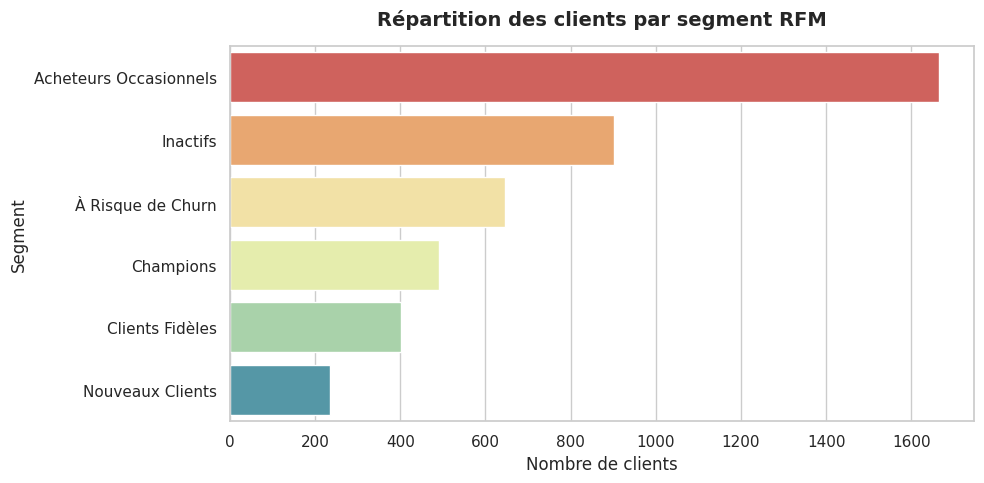

In [7]:
segment_counts = rfm['Segment'].value_counts().reset_index()
segment_counts.columns = ['Segment', 'Count']

plt.figure(figsize=(10, 5))
sns.barplot(data=segment_counts, x='Count', y='Segment', palette='Spectral')
plt.title("Répartition des clients par segment RFM", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Nombre de clients", fontsize=12)
plt.ylabel("Segment", fontsize=12)
plt.tight_layout()
plt.show()